# Figure S8

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import load_loo_comparison, DATASET_LABELS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
BASELINE_MODEL = "HDDM_Base_Pupil"

### Helper functions

In [2]:
def style_axis(ax, col=None, ylabel=None, xlabel=None, xlabel_col=1):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0 and ylabel:
        ax.set_ylabel(ylabel)
    if col == xlabel_col and xlabel:
        ax.set_xlabel(xlabel)


def _lookup_elpd_diff(loo_df, baseline_model, model_id, column):
    """One (reference_model, target_model) row's diff column from a pairwise
    LOO comparison table (compare_models.py's compare_pair output)."""
    row = loo_df[(loo_df["reference_model"] == baseline_model)
                 & (loo_df["target_model"] == model_id)]
    if len(row) != 1:
        raise ValueError(
            f"Expected exactly one {baseline_model} vs {model_id} row in the "
            f"LOO comparison table, found {len(row)} -- check MODEL_GROUPS in "
            f"compare_models.py."
        )
    return row[column].iloc[0]


def compute_elpd_vs_baseline(dataset, baseline_model, model_order, column="diff_elpd_loo"):
    """LOO elpd diff (all trials shared by each pair) vs. baseline_model,
    read directly off compare_models.py's pairwise comparison table."""
    loo = load_loo_comparison(dataset, group_name="arousal")
    return [_lookup_elpd_diff(loo, baseline_model, m, column) for m, _ in model_order]


def compute_elpd_robustness_vs_baseline(dataset, baseline_model, model_order,
                                        column="diff_elpd_reliable"):
    """Same as compute_elpd_vs_baseline, restricted to trials reliable
    (pareto_k <= 0.7) in both models of each pair."""
    loo = load_loo_comparison(dataset, group_name="arousal")
    return [_lookup_elpd_diff(loo, baseline_model, m, column) for m, _ in model_order]


ELPD_THRESHOLD = 4

ELPD_COLORS = {
    "improved":  "#017D01",
    "ambiguous": "#8D8D8D",
    "worse":     "#980B0B",
}
ELPD_LABELS = {
    "improved":  "∆elpd > 4",
    "ambiguous": "otherwise",
    "worse":     "∆elpd < -4",
}


def elpd_category(diff):
    if diff > ELPD_THRESHOLD:
        return "improved"
    if diff < -ELPD_THRESHOLD:
        return "worse"
    return "ambiguous"


def plot_elpd_bars(ax, diffs, x_labels, col, ylim, show_legend=False):
    x_pos = np.arange(len(diffs))
    colors = [ELPD_COLORS[elpd_category(d)] for d in diffs]
    ax.bar(x_pos, diffs, color=colors, width=0.6, zorder=3)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.set_ylim(ylim)
    style_axis(ax, col, ylabel="Improvement over\nbaseline DDM (∆elpd-loo)",
              xlabel="DDM parameter with decision-related pupil interaction")

    if show_legend:
        handles = [mpatches.Patch(facecolor=ELPD_COLORS[cat], label=ELPD_LABELS[cat])
                  for cat in ("improved", "worse", "ambiguous")]
        ax.legend(handles=handles, loc="upper left")

### Figure S8
Model comparison: `HDDM_Base_Pupil_ndt` (NDT x Pupil), `HDDM_Base_Pupil_boundary` (Boundary x Pupil), and `HDDM_Base_Pupil_valuation` (Valuation x Pupil), each vs. the baseline `HDDM_Base_Pupil`, one panel per dataset. Below: the PSIS-LOO robustness check for the same comparisons (∆elpd restricted to trials reliable in both models, `diff_elpd_reliable`).

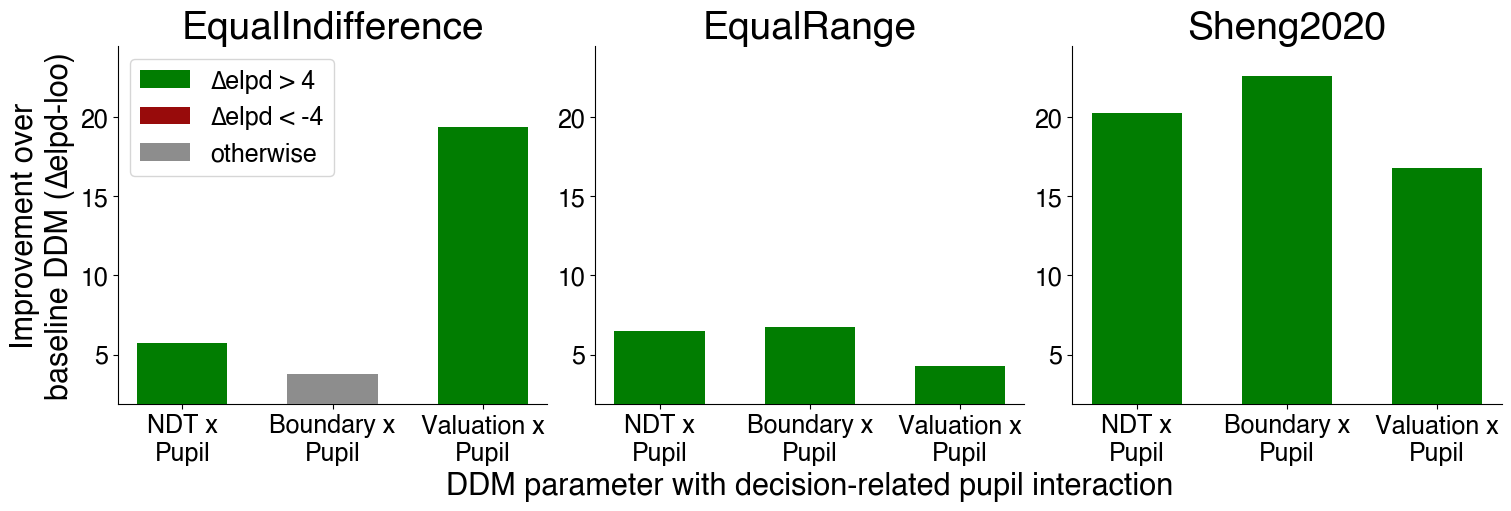

In [3]:
ELPD_MODEL_ORDER = [
    ("HDDM_Base_Pupil_ndt",       "NDT x\nPupil"),
    ("HDDM_Base_Pupil_boundary",  "Boundary x\nPupil"),
    ("HDDM_Base_Pupil_valuation", "Valuation x\nPupil"),
]

elpd_labels = [label for _, label in ELPD_MODEL_ORDER]
elpd_vs_baseline = {ds: compute_elpd_vs_baseline(ds, BASELINE_MODEL, ELPD_MODEL_ORDER) for ds in DATASETS}

all_diffs = [d for diffs in elpd_vs_baseline.values() for d in diffs]
margin = 0.1 * (max(all_diffs) - min(all_diffs))
elpd_ylim = (min(all_diffs) - margin, max(all_diffs) + margin)

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), layout="constrained")

for col, ds in enumerate(DATASETS):
    plot_elpd_bars(axes[col], elpd_vs_baseline[ds], elpd_labels, col, elpd_ylim, show_legend=(col == 0))
    axes[col].set_title(DATASET_LABELS.get(ds, ds))

fig.savefig("saved/figureS8.svg", dpi=300, bbox_inches="tight")
plt.show()

### Robustness check
Per dataset: ∆elpd (baseline vs. model, from the figure above, `diff_elpd_loo` — all trials shared by the pair) next to the PSIS-LOO robustness-check ∆elpd (same comparison restricted to trials reliable in both models, `diff_elpd_reliable`).

In [4]:
for ds in DATASETS:
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, BASELINE_MODEL, ELPD_MODEL_ORDER)
    summary = pd.DataFrame({
        "model": [label.replace("\n", " ") for label in elpd_labels],
        "delta_elpd": elpd_vs_baseline[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
            model  delta_elpd  delta_elpd_robust
      NDT x Pupil    5.727079           2.206255
 Boundary x Pupil    3.773395           1.951270
Valuation x Pupil   19.396224          19.352006

equalRange
            model  delta_elpd  delta_elpd_robust
      NDT x Pupil    6.494879           6.527266
 Boundary x Pupil    6.773745           3.698192
Valuation x Pupil    4.273741           2.751314

sheng2020
            model  delta_elpd  delta_elpd_robust
      NDT x Pupil   20.261836          25.500383
 Boundary x Pupil   22.566798          23.602952
Valuation x Pupil   16.763485          17.375015
